In [ ]:
# 最適化：損失関数の値をできるだけ小さくするパラメータを見つけること
# 最適化を行うクラスを分離して実装することで、最適化手法を容易に切り替えられるようにすることが一般的

In [1]:
# 確率的勾配降下法（SGD）によって、パラメータを更新するだけのクラスとして定義
# SGDの欠点は、関数の形状が等方的でないと、非効率な経路で探索をしてしまうこと
# ↑勾配の方向が、本来の最小値ではない方向を指してしまうことが根本的な原因

# 使用例）
# optimizer = SGD()
# ...
# optimizer.update(params, grads) # パラメータを更新するだけ
# ...
class SGD:
    def __init__(self, lr=0.01):
        self.lr = lr

    def update(self, params, grads):
        for key in params.keys():
            params[key] -= self.lr * grads[key]

$$
\boldsymbol{W} \leftarrow \boldsymbol{W} - \eta \frac{\partial L}{\partial \boldsymbol{W}}
$$

In [2]:
# Momentum
# 速度 v という変数を追加し、学習の仕方が慣性が存在するような形状になる
# ↑計算上では、バッチごとに v に対して加算していくことで慣性を表現する
class Momentum:
    def __init__(self, lr=0.01, momentum=0.9):
        self.lr = lr
        self.momentum = momentum
        self.v = None

    def update(self, params, grads):
        if self.v is None:
            self.v = {}
            for key, val in params.items():
                self.v[key] = np.zero_like(val)
        for key in params.keys():
            self.v[key] = self.momentum * self.v[key] - self.lr * grads[key]
            params[key] += self.v[key]

$$
\begin{aligned}
\boldsymbol{v} &\leftarrow \alpha \boldsymbol{v} - \eta \frac{\partial L}{\partial \boldsymbol{W}} \\
\boldsymbol{W} &\leftarrow \boldsymbol{W} + \boldsymbol{v}
\end{aligned}
$$

In [4]:
# AdaGrad
# 学習係数を、パラメータの要素ごとに適応的に調整しながら学習を行う方法
# 学習を進めるほど、学習係数が減衰していく（学習係数の減衰）
# ↑まだ収束していないのに、学習係数がほぼ0になってしまうことがあり、
#  これを改善した手法として RMSPropという方法がある（指数移動平均を使用する）
class AdaGrad:
    def __init__(self, lr=0.01):
        self.lr = lr
        self.h = None

    def update(self, params, grads):
        if self.h is None:
            self.h = {}
            for key, val in params.items():
                self.h[key] = np.zero_like(val)
        for key in params.keys():
            self.h[key] += grads[key] * grads[key] 
            params[key] -= self.lr * grads[key] / (np.sqrt(self.h[key]) + 1e-7)

$$
\begin{aligned}
\boldsymbol{h} &\leftarrow \boldsymbol{h} + \frac{\partial L}{\partial \boldsymbol{W}} \odot \frac{\partial L}{\partial \boldsymbol{W}} \\
\boldsymbol{W} &\leftarrow \boldsymbol{W} - \eta \frac{1}{\sqrt{\boldsymbol{h}}} \frac{\partial L}{\partial \boldsymbol{W}}
\end{aligned}
$$

In [ ]:
# Adam （ Momentum + AdaGrad ）
# ハイパーパラメータのバイアス補正も行われる

In [ ]:
# 重みの初期化

# 重みの初期値をすべて 0 にしてしまうのは、悪いアイデア（重みを均一にすること自体がよろしくない）
# 誤差逆伝播法において、重みが均一だと、すべての重みの値が均一に更新されてしまうため

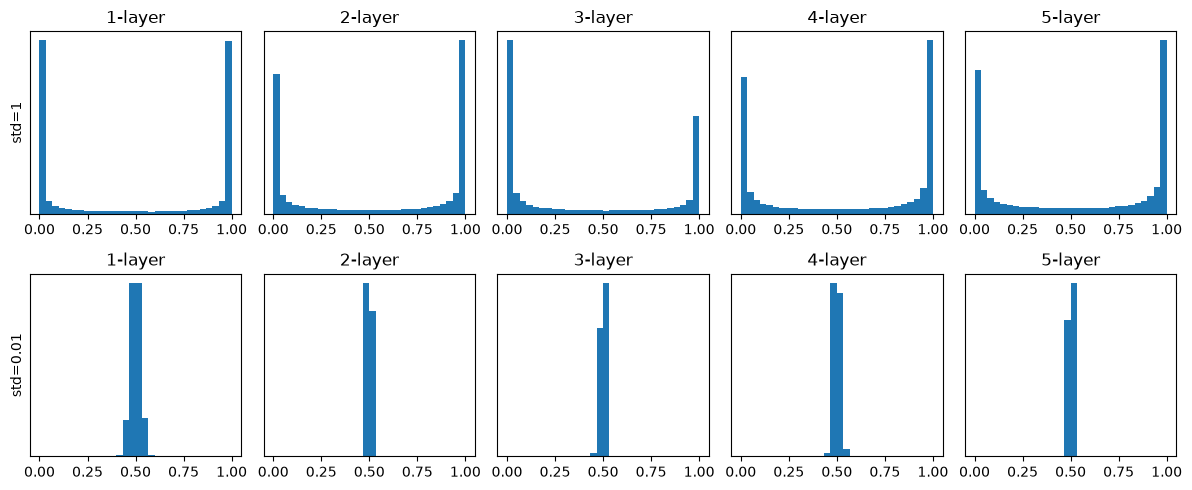

In [9]:
# 隠れ層のアクティベーション（活性化関数の後の出力データ）分布
# 0と1に偏ったデータ分布では、逆伝播で勾配の値が小さくなっていき消失してしまう（勾配消失）
# 0と1の偏りが小さいと勾配消失は起きないが、偏りが生まれることで表現力に制限がかかってしまう
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

input_data = np.random.randn(1000, 100) # 両方で同じ入力を使う

node_num = 100        # 隠れ層のニューロン（ノード）の数
hidden_layer_size = 5 # 隠れ層が5層

# 重みの標準偏差を変えて、各層のアクティベーションを計算する
def calc_activations(weight_scale):
    x = input_data
    activations = {}
    for i in range(hidden_layer_size):
        if i != 0:
            x = activations[i-1]

        w = np.random.randn(node_num, node_num) * weight_scale

        z = np.dot(x, w)
        a = sigmoid(z)
        activations[i] = a
    return activations

weight_scales = [1, 0.01] # 上段: 1、下段: 0.01

plt.figure(figsize=(12, 5))
for row, scale in enumerate(weight_scales):
    activations = calc_activations(scale)
    for i, a in activations.items():
        plt.subplot(len(weight_scales), hidden_layer_size, row * hidden_layer_size + i + 1)
        plt.title(str(i+1) + "-layer")
        plt.hist(a.flatten(), 30, range=(0, 1))
        plt.yticks([])
        if i == 0:
            plt.ylabel("std=" + str(scale)) # 行の左端に、どちらの設定かを表示
plt.tight_layout()
plt.show()

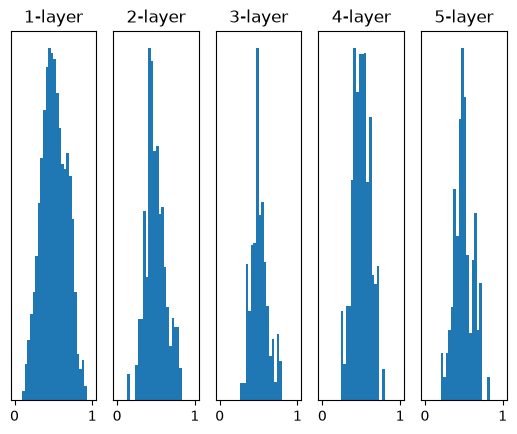

In [10]:
# Xavierの初期値: 前の層のノード数を n として、標準偏差 1/√n の正規分布で初期化

for i in range(hidden_layer_size):
    if i != 0:
        x = activations[i-1]

    w = np.random.randn(node_num, node_num) / np.sqrt(node_num) # ここ

    z = np.dot(x, w)
    a = sigmoid(z)
    activations[i] = a

for i, a in activations.items():
    plt.subplot(1, len(activations), i+1)
    plt.title(str(i+1) + "-layer")
    plt.hist(a.flatten(), 30, range=(0, 1))
    plt.yticks([])
plt.show()

In [ ]:
# 活性化関数に、ReLU などの線形関数に近似できないものを使用する場合は、
# He の初期値を使用すると良い（Xavierの √２ 倍の値で割るだけ）

In [ ]:
# Batch Normalization
# アクティベーションの分布を、適度な広がりを持つように調整する
# Affineレイヤ と Lossレイヤ の間に差し込むことで、データ分布の正規化を行う

# 効果として、
# ・学習を早く進行させることができる（学習係数を大きくすることができる）
# ・初期値にそれほど依存しない
# ・過学習を抑制する

In [ ]:
# Weight Decay （荷重減衰）
# 過学習抑制手法の1つ
# 学習の過程で、大きな重みを持つことに対してペナルティを課すことで、過学習を抑制する
# L2正則化と呼ばれるタイプの正則化を施す

$$
L' = L + \frac{1}{2} \lambda \sum_{l} \lVert \boldsymbol{W}^{(l)} \rVert^2
$$

$$
\frac{\partial L'}{\partial \boldsymbol{W}} = \frac{\partial L}{\partial \boldsymbol{W}} + \lambda \boldsymbol{W}
$$

In [12]:
# Dropout
# ニューロンをランダムに削除しながら学習する方法
# モデルが複雑になってくると、 Weight Decay では対応が困難になってくる
class Dropout:
    def __init__(self, dropout_ratio=0.5):
        self.dropout_ratio = dropout_ratio
        self.mask = None

    def forward(self, x, train_flg=True):
        if train_flg:
            self.mask = np.random.rand(*x.shape) > self.dropout_ratio
            return x * self.mask
        else:
            return x * (1.0 - self.dropout_ratio)

    def backward(self, dout):
        return dout * self.mask

In [ ]:
# データの分離
# ・訓練データ：パラメータ（重みやバイアス）の学習に使用する
# ・検証データ：ハイパーパラメータの性能を評価するために使用する
# ・テストデータ：汎化性能をチェックするために使用する

# ハイパーパラメータの最適化の手順（下記以外にも、ベイズ最適化などの洗練された手法がある）
# 0. ハイパーパラメータの範囲を設定する（10の冪乗スケールで設定すると良い）
# 1. 範囲の中から、ランダムにサンプリングする
# 2. サンプリングした値で学習を行い、検証データで認識精度を評価する
# 3. 上記を繰り返し、認識精度から最適なハイパーパラメータの範囲を狭める
# 4. ある程度狭まったら、最終的なパラメータの値を1つピックアップする